# Day 1 · Notebook 3 — The SLAM back-end: pose-graph optimisation

Visual odometry drifts. The back-end fixes this by putting **all** poses into one optimisation problem.

* **Nodes**: robot poses $\mathbf{x}_i = (x_i, y_i, \theta_i)$ (2D here, to keep it simple; same idea in 3D)
* **Edges**: relative-pose measurements $\mathbf{z}_{ij}$ with information (inverse covariance) $\Omega_{ij}$
  * **odometry** edges between consecutive poses: $j = i+1$
  * **loop-closure** edges: "I am back at a place I saw before" (from place recognition + geometric verification)

We write a Gauss–Newton solver from scratch (about 40 lines) and watch the loop snap shut.

Reference: Grisetti, Kümmerle, Stachniss, Burgard, *A Tutorial on Graph-Based SLAM*, IEEE ITS Magazine 2010.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.sparse as sp
import scipy.sparse.linalg as spla

def wrap(a):
    return (a + np.pi) % (2 * np.pi) - np.pi

def v2t(p):
    """(x, y, theta) -> 3x3 homogeneous transform."""
    c, s = np.cos(p[2]), np.sin(p[2])
    return np.array([[c, -s, p[0]], [s, c, p[1]], [0, 0, 1]])

def t2v(T):
    return np.array([T[0, 2], T[1, 2], np.arctan2(T[1, 0], T[0, 0])])

## 1 · Simulate a robot driving two laps around a block

Ground truth is a rounded rectangle. The robot only knows its **noisy odometry**. Integrating it (*dead reckoning*) gives the initial guess, which drifts.

When the robot passes close to an earlier pose, we add a **loop-closure** edge. In a real system this comes from place recognition (Day 2!) + RANSAC.

201 poses, 200 odometry edges, 27 loop closures


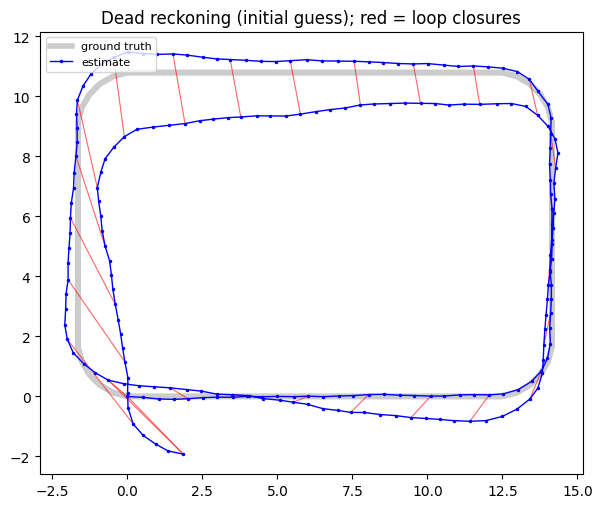

In [2]:
rng = np.random.default_rng(42)

# ground-truth trajectory: 2 laps of a rounded rectangle, 0.5 m steps
# one lap = long side, 90° turn, short side, 90° turn, long side, turn, short side, turn
gt = [np.array([0.0, 0.0, 0.0])]
side = lambda n: [(0.5, 0.0)] * n
turn = [(0.5, np.pi / 2 / 6)] * 6                      # 90° spread over 6 steps
moves = (side(24) + turn + side(14) + turn) * 4         # 2 long + 2 short sides per lap, 2 laps
for d, dth in moves:
    gt.append(t2v(v2t(gt[-1]) @ v2t([d, 0, dth])))
gt = np.array(gt)
N = len(gt)

sigma_odo = np.array([0.03, 0.03, np.radians(1.0)])     # odometry noise (x, y, theta)
sigma_lc = np.array([0.05, 0.05, np.radians(1.0)])      # loop-closure noise

edges = []   # (i, j, z_ij, Omega_ij, kind)
for i in range(N - 1):
    z = t2v(np.linalg.inv(v2t(gt[i])) @ v2t(gt[i + 1])) + rng.normal(0, sigma_odo)
    edges.append((i, i + 1, z, np.diag(1 / sigma_odo**2), "odom"))
for i in range(0, N, 4):                     # check every 4th pose (keeps the plot readable)
    for j in range(i + 30, N):
        if np.linalg.norm(gt[i, :2] - gt[j, :2]) < 0.4:
            z = t2v(np.linalg.inv(v2t(gt[i])) @ v2t(gt[j])) + rng.normal(0, sigma_lc)
            edges.append((i, j, z, np.diag(1 / sigma_lc**2), "loop"))
print(N, "poses,", sum(e[4] == "odom" for e in edges), "odometry edges,",
      sum(e[4] == "loop" for e in edges), "loop closures")

# initial guess: dead reckoning (chain the odometry)
init = [gt[0].copy()]
for i, j, z, _, kind in edges:
    if kind == "odom":
        init.append(t2v(v2t(init[-1]) @ v2t(z)))
init = np.array(init)

def plot_graph(x, title, ax=None, show_loops=True):
    ax = ax or plt.gca()
    ax.plot(gt[:, 0], gt[:, 1], "-", color="0.8", lw=4, label="ground truth")
    if show_loops:
        for i, j, _, _, kind in edges:
            if kind == "loop":
                ax.plot(x[[i, j], 0], x[[i, j], 1], "r-", lw=0.8, alpha=0.6)
    ax.plot(x[:, 0], x[:, 1], "b.-", ms=3, lw=1, label="estimate")
    ax.set_aspect("equal"); ax.set_title(title); ax.legend(loc="upper left", fontsize=8)

plt.figure(figsize=(7, 6)); plot_graph(init, "Dead reckoning (initial guess); red = loop closures"); plt.show()

## 2 · The error of one edge

The measurement says "$\mathbf{x}_j$ seen from $\mathbf{x}_i$ is $\mathbf{z}_{ij}$". The current estimate predicts $X_i^{-1}X_j$. The error is the difference, written in the frame of the measurement:

$$ \mathbf{e}_{ij}(\mathbf{x}) = \mathrm{t2v}\!\left(Z_{ij}^{-1}\,(X_i^{-1} X_j)\right) \in \mathbb{R}^3 $$

and SLAM becomes a **nonlinear least-squares** problem:

$$ \mathbf{x}^* = \arg\min_{\mathbf{x}} \sum_{(i,j)} \mathbf{e}_{ij}^\top\, \Omega_{ij}\, \mathbf{e}_{ij} $$

## 3 · Gauss–Newton

Linearise each error around the current guess: $\mathbf{e}_{ij}(\mathbf{x} + \Delta\mathbf{x}) \approx \mathbf{e}_{ij} + A_{ij}\Delta\mathbf{x}_i + B_{ij}\Delta\mathbf{x}_j$. Then:

$$ H\,\Delta\mathbf{x} = -\mathbf{b}, \qquad H = \sum J_{ij}^\top \Omega_{ij} J_{ij}, \qquad \mathbf{b} = \sum J_{ij}^\top \Omega_{ij}\, \mathbf{e}_{ij}, \qquad \mathbf{x} \leftarrow \mathbf{x} + \Delta\mathbf{x} $$

Each edge only touches blocks $(i,i), (i,j), (j,i), (j,j)$ of $H$, so **$H$ is sparse**. That's why SLAM back-ends scale to huge maps. We also fix $\mathbf{x}_0$ (the *gauge*), otherwise the whole map could slide freely.

Jacobians for SE(2) (Grisetti et al.), with $R_i = R(\theta_i)$, $R_{ij} = R(\theta_{z_{ij}})$:

$$
A_{ij} = \begin{bmatrix} -R_{ij}^\top R_i^\top & R_{ij}^\top \tfrac{\partial R_i^\top}{\partial\theta_i}(\mathbf{t}_j - \mathbf{t}_i) \\ \mathbf{0}^\top & -1 \end{bmatrix},
\qquad
B_{ij} = \begin{bmatrix} R_{ij}^\top R_i^\top & \mathbf{0} \\ \mathbf{0}^\top & 1 \end{bmatrix}
$$

In [3]:
def rot(th):
    return np.array([[np.cos(th), -np.sin(th)], [np.sin(th), np.cos(th)]])

def edge_error_jacobians(xi, xj, z):
    Ri, Rz = rot(xi[2]), rot(z[2])
    dt = xj[:2] - xi[:2]
    e = np.r_[Rz.T @ (Ri.T @ dt - z[:2]), wrap(xj[2] - xi[2] - z[2])]
    dRiT = np.array([[-np.sin(xi[2]), np.cos(xi[2])], [-np.cos(xi[2]), -np.sin(xi[2])]])
    A = np.zeros((3, 3)); B = np.zeros((3, 3))
    A[:2, :2] = -Rz.T @ Ri.T; A[:2, 2] = Rz.T @ dRiT @ dt; A[2, 2] = -1
    B[:2, :2] = Rz.T @ Ri.T; B[2, 2] = 1
    return e, A, B

# sanity check: analytic vs numerical Jacobian
xi, xj, z = np.array([1, 2, 0.3]), np.array([2, 2.5, 0.9]), np.array([0.9, 0.4, 0.5])
e0, A, B = edge_error_jacobians(xi, xj, z)
num_A = np.stack([(edge_error_jacobians(xi + d, xj, z)[0] - e0) / 1e-6 for d in np.eye(3) * 1e-6], 1)
print("max |A - numerical A| =", np.abs(A - num_A).max().round(6))

def total_cost(x):
    cost = 0.0
    for i, j, z, Om, _ in edges:
        e = edge_error_jacobians(x[i], x[j], z)[0]
        cost += e @ Om @ e
    return cost

def gauss_newton_step(x):
    n = len(x)
    rows, cols, vals = [], [], []
    b = np.zeros(3 * n)
    for i, j, z, Om, _ in edges:
        e, A, B = edge_error_jacobians(x[i], x[j], z)
        blocks = {(i, i): A.T @ Om @ A, (i, j): A.T @ Om @ B, (j, i): B.T @ Om @ A, (j, j): B.T @ Om @ B}
        for (r, c), blk in blocks.items():
            rr, cc = np.meshgrid(np.arange(3 * r, 3 * r + 3), np.arange(3 * c, 3 * c + 3), indexing="ij")
            rows.append(rr.ravel()); cols.append(cc.ravel()); vals.append(blk.ravel())
        b[3 * i:3 * i + 3] += A.T @ Om @ e
        b[3 * j:3 * j + 3] += B.T @ Om @ e
    H = sp.coo_matrix((np.concatenate(vals), (np.concatenate(rows), np.concatenate(cols))), shape=(3 * n, 3 * n)).tocsr()
    H = H + sp.diags(np.r_[np.full(3, 1e6), np.zeros(3 * n - 3)])     # fix pose 0 (gauge)
    dx = spla.spsolve(H.tocsc(), -b).reshape(n, 3)
    x_new = x + dx; x_new[:, 2] = wrap(x_new[:, 2])
    return x_new, H

max |A - numerical A| = 1e-06


iter 0: cost =      46180.9
iter 1: cost =        344.2
iter 2: cost =         67.0
iter 3: cost =         66.3
iter 4: cost =         66.3
iter 5: cost =         66.3
iter 6: cost =         66.3
iter 7: cost =         66.3


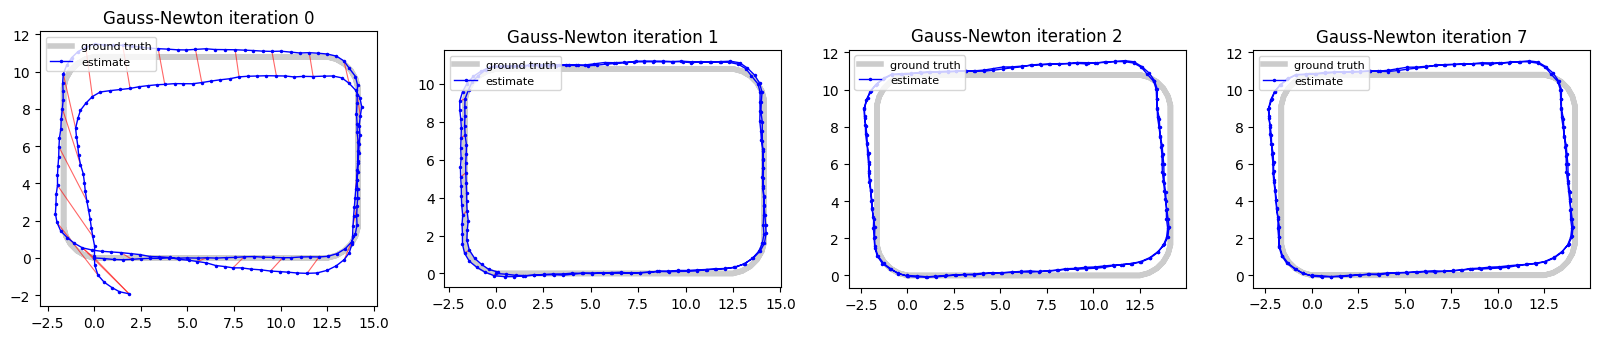

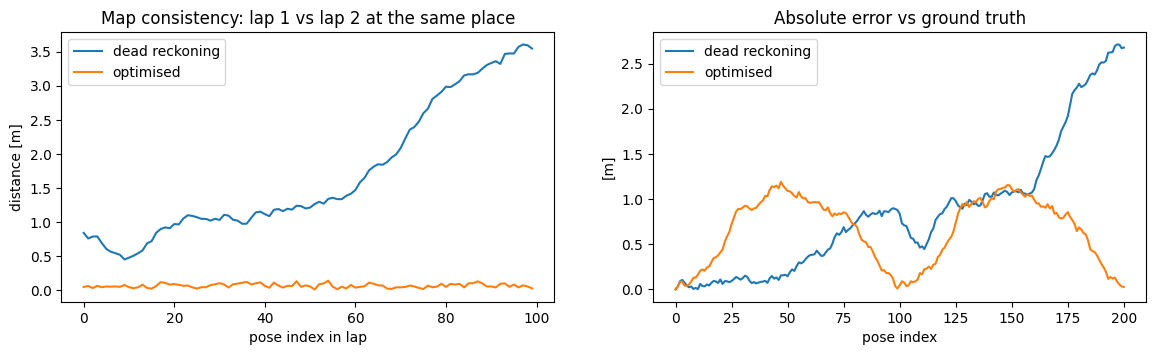

lap-to-lap inconsistency: 1.69 m -> 0.06 m
absolute error (mean)   : 0.86 m -> 0.65 m
The map becomes self-consistent. Some absolute error stays: without GPS or known landmarks,
nothing tells the robot where the 'true' world frame is, only that it has been here before.


In [4]:
x = init.copy()
history = [x.copy()]
print(f"iter 0: cost = {total_cost(x):12.1f}")
for it in range(1, 8):
    x, H = gauss_newton_step(x)
    history.append(x.copy())
    print(f"iter {it}: cost = {total_cost(x):12.1f}")

fig, axs = plt.subplots(1, 4, figsize=(20, 5))
for ax, k in zip(axs, [0, 1, 2, len(history) - 1]):
    plot_graph(history[k], f"Gauss-Newton iteration {k}", ax)
plt.show()

err_init = np.linalg.norm(init[:, :2] - gt[:, :2], axis=1)
err_opt = np.linalg.norm(x[:, :2] - gt[:, :2], axis=1)
lap = N // 2                                   # pose i and i + lap are the same place
gap_init = np.linalg.norm(init[:lap, :2] - init[lap:2 * lap, :2], axis=1)
gap_opt = np.linalg.norm(x[:lap, :2] - x[lap:2 * lap, :2], axis=1)

fig, axs = plt.subplots(1, 2, figsize=(14, 3.5))
axs[0].plot(gap_init, label="dead reckoning"); axs[0].plot(gap_opt, label="optimised")
axs[0].set_title("Map consistency: lap 1 vs lap 2 at the same place"); axs[0].set_xlabel("pose index in lap")
axs[0].set_ylabel("distance [m]"); axs[0].legend()
axs[1].plot(err_init, label="dead reckoning"); axs[1].plot(err_opt, label="optimised")
axs[1].set_title("Absolute error vs ground truth"); axs[1].set_xlabel("pose index"); axs[1].set_ylabel("[m]"); axs[1].legend()
plt.show()
print(f"lap-to-lap inconsistency: {gap_init.mean():.2f} m -> {gap_opt.mean():.2f} m")
print(f"absolute error (mean)   : {err_init.mean():.2f} m -> {err_opt.mean():.2f} m")
print("The map becomes self-consistent. Some absolute error stays: without GPS or known landmarks,")
print("nothing tells the robot where the 'true' world frame is, only that it has been here before.")

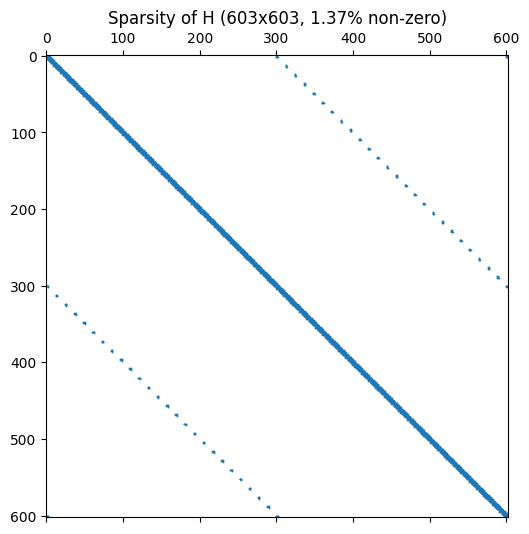

In [5]:
# The structure of H: odometry gives a band, every loop closure adds an off-diagonal block.
plt.figure(figsize=(6, 6)); plt.spy(H, markersize=0.3)
plt.title(f"Sparsity of H ({H.shape[0]}x{H.shape[0]}, {100 * H.nnz / H.shape[0]**2:.2f}% non-zero)"); plt.show()

## 4 · What if there were no loop closures?

Drop the loop edges: the optimiser has nothing to correct with, so the result is just dead reckoning. **Loop closure is what makes it SLAM.**

In [6]:
all_edges = edges
edges = [e for e in all_edges if e[4] == "odom"]
x_no_lc = init.copy()
for _ in range(5):
    x_no_lc, _ = gauss_newton_step(x_no_lc)
edges = all_edges
print("final position error without loop closures: %.2f m" % np.linalg.norm(x_no_lc[-1, :2] - gt[-1, :2]))
print("final position error with loop closures   : %.2f m" % np.linalg.norm(x[-1, :2] - gt[-1, :2]))

final position error without loop closures: 2.68 m
final position error with loop closures   : 0.03 m


## 5 · Same machinery, different error: bundle adjustment

In visual SLAM / SfM the unknowns are **camera poses and 3D points**, and the error is the **reprojection error**:

$$ \min_{\{R_i, \mathbf{t}_i\},\, \{\mathbf{X}_j\}} \sum_{(i,j)\,\in\,\text{observations}} \rho\!\left( \big\| \pi\!\left(K(R_i\mathbf{X}_j + \mathbf{t}_i)\right) - \mathbf{x}_{ij} \big\|^2 \right) $$

* $\rho$: a robust loss (Huber / Cauchy) so leftover outliers don't dominate
* solved with Levenberg–Marquardt (Gauss–Newton + damping) using the sparse **Schur complement** trick
* tools: Ceres (COLMAP), g2o (ORB-SLAM), GTSAM

| | Pose graph | Bundle adjustment |
|---|---|---|
| unknowns | poses | poses + 3D points (+ intrinsics) |
| measurement | relative pose $\mathbf{z}_{ij}$ | pixel $\mathbf{x}_{ij}$ |
| cost | cheap, large maps | accurate, more expensive |
| typical use | loop closing over the whole map | local windows (ORB-SLAM), full SfM (COLMAP) |

Notebook 5 runs COLMAP, whose last step is exactly this BA.